In [ ]:
import tensorflow as tf
import numpy as np
from tensorflow.keras import layers, models
from keras.models import Model
import os
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

path = '/content/drive/MyDrive/Libras'
os.chdir(path)

Mounted at /content/drive


In [ ]:
# ===========================
# 0. Importar Bibliotecas
# ===========================

# Imports Essenciais
from google.colab import drive # Para montar o Google Drive
import os                      # Para manipulação de caminhos e arquivos
import numpy as np             # Para arrays (matrizes)
import tensorflow as tf        # Core do Keras
import matplotlib.pyplot as plt # Para gráficos

# Imports para a Arquitetura CNN e Treinamento
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, LayerNormalization
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.models import load_model # Usaremos load_model para o modelo completo (Adam + arquitetura)

#IMPORTS ADICIONAIS PARA O CALLBACK PERSONALIZADO
from IPython.display import clear_output # CRÍTICO para o gráfico atualizar no Colab
import pandas as pd # Necessário para ler/salvar o CSV de métricas no callback

from tensorflow.keras.optimizers import Adam


In [ ]:
# Tamanho das imagens
img_height = 240
img_width = 240
batch_size = 32

# Diretórios
base_dir = "/content/drive/MyDrive/Libras/dataset"


train_dir = f"{base_dir}/train"
val_dir = f"{base_dir}/val"
test_dir = f"{base_dir}/test"

# Carrega os dados diretamente dos diretórios
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode="int",  # ou "categorical" se quiser one-hot
    shuffle=True,
    seed=123
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    val_dir,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode="int",
    shuffle=True,
    seed=123
)

test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    test_dir,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode="int",
    shuffle=False  # Não embaralhar teste, para facilitar avaliação posterior
)

# Verifica as classes detectadas
class_names = train_ds.class_names
print("Classes detectadas:", class_names)

# Melhora desempenho com prefetching
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)


Found 1470 files belonging to 3 classes.
Found 315 files belonging to 3 classes.
Found 315 files belonging to 3 classes.
Classes detectadas: ['A', 'B', 'C']


# Modelo

In [ ]:
data_augmentation = Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
])

In [ ]:
# Modelo
# Aqui vai seu modelo
model = Sequential([
    # Camada de Re-escalonamento: Normaliza os pixels de 0-255 para 0-1
    tf.keras.layers.Rescaling(1./255, input_shape=(img_height, img_width, 3)),

    data_augmentation,

    # Bloco Convolucional 1
    Conv2D(12, (3, 3), activation='relu'),#4
    MaxPooling2D((2, 2)),

    # Bloco Convolucional 2
    Conv2D(14, (3, 3), activation='relu'),#8
    MaxPooling2D((2, 2)),

    Conv2D(16, (3, 3), activation='relu'),#8
    MaxPooling2D((2, 2)),

    # Camadas DENSE (Classificador)
    Flatten(),
    Dense(12, activation='relu'),     #12

    # Camada de Saída (units=NUM_CLASSES (3) e softmax para probabilidades)
    Dense(units=3, activation='softmax')
])

# Compila o modelo
model.compile(
    optimizer = Adam(learning_rate=0.0001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)


# Treinamento

In [ ]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Treinamento
history = model.fit(
  train_ds,
  validation_data=val_ds,
  callbacks=[early_stopping],
  epochs=300
)

Epoch 1/300
46/46 ━━━━━━━━━━━━━━━━━━━━ 8s 115ms/step - accuracy: 0.3463 - loss: 1.0994 - val_accuracy: 0.3333 - val_loss: 1.0951
Epoch 2/300
46/46 ━━━━━━━━━━━━━━━━━━━━ 6s 122ms/step - accuracy: 0.3663 - loss: 1.0905 - val_accuracy: 0.3683 - val_loss: 1.0815
Epoch 3/300
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 109ms/step - accuracy: 0.4016 - loss: 1.0806 - val_accuracy: 0.3587 - val_loss: 1.0651
Epoch 4/300
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 112ms/step - accuracy: 0.4593 - loss: 1.0589 - val_accuracy: 0.4762 - val_loss: 1.0328
Epoch 5/300
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 116ms/step - accuracy: 0.4979 - loss: 1.0370 - val_accuracy: 0.4730 - val_loss: 1.0001
Epoch 6/300
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 124ms/step - accuracy: 0.4756 - loss: 1.0035 - val_accuracy: 0.6063 - val_loss: 0.9406
Epoch 7/300
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - accuracy: 0.5180 - loss: 0.9584 - val_accuracy: 0.4413 - val_loss: 0.9405
Epoch 8/300
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 112ms/step - accuracy: 0.5152 - loss: 0.9343 - val_acc

## Avaliação

In [ ]:
# Avaliação final
test_loss, test_acc = model.evaluate(test_ds)
print(f"\nAcurácia no conjunto de teste: {test_acc:.2%}")

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step - accuracy: 0.9003 - loss: 0.2736

Acurácia no conjunto de teste: 91.75%


## Salvamento

In [ ]:
model.save("modelo.keras")

In [ ]:
model.export("modelofinal")

Saved artifact at 'modelofinal'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 240, 240, 3), dtype=tf.float32, name='keras_tensor_82')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  139673357356304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673357364752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673357354000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673357357072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673357356496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673357363600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673357364368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673357356112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673357359952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673357357840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673357364944:

# Carregando o Modelo

In [ ]:
MODEL_DIR = "model"
# Carrega o modelo salvo
#loaded = tf.saved_model.load(MODEL_DIR)
loaded = tf.keras.models.load_model("modelo.keras")


# Obtém a assinatura padrão
#concrete_func = loaded.signatures["serving_default"]

# Extrai o nome real da entrada
#input_tensor_name = list(concrete_func.structured_input_signature[1].keys())[0]
#print(input_tensor_name)


## Conversão e Quantização

In [ ]:
## converte um modelo a partir do modelo original sem salvar
## Converter sem quantização
converter1 = tf.lite.TFLiteConverter.from_keras_model(loaded)
converted1 = converter1.convert()

## converter com quantização int8
rep_ds = train_ds.unbatch().batch(1)
def representative_data_gen():
    for input_value, _ in rep_ds.take(100):
        image = input_value.numpy().astype(np.float32)
        yield [image]

converter2 = tf.lite.TFLiteConverter.from_keras_model(loaded)
converter2.optimizations = [tf.lite.Optimize.DEFAULT]
converter2.representative_dataset = representative_data_gen
converter2.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter2.inference_input_type = tf.int8
converter2.inference_output_type = tf.int8
converted2 = converter2.convert()

Saved artifact at '/tmp/tmpmlqg4f_m'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 240, 240, 3), dtype=tf.float32, name='input_layer_8')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  139672612798096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139672612797712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139672612796752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139672612796560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139672612797328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139672612797136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139672612796368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139672612795984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139672612797904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139672612797520: TensorSpec(shape=(), dtype=tf.resource, name=None)
Saved artifact 

/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/convert.py:854: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


[{'name': 'serving_default_input_layer_8:0', 'index': 0, 'shape': array([  1, 240, 240,   3], dtype=int32), 'shape_signature': array([ -1, 240, 240,   3], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}]
[{'name': 'StatefulPartitionedCall_1:0', 'index': 21, 'shape': array([1, 3], dtype=int32), 'shape_signature': array([-1,  3], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}]
[{'name': 'serving_default_input_layer_8:0', 'index': 0, 'shape': array([  1, 240, 240,   3], dtype=int32), 'shape_signature': array([ -1, 240, 240,   3], dtype=int32), 'dtype': <class 'numpy.int8'>, 'quantization': (1.0, -128), 'quantization_parameters':

/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


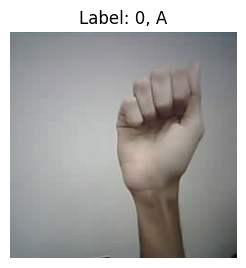

shape: (240, 240, 3)
tipo: float32
min: 7.0
max: 219.0
tipo: int8
min: -121
max: 91
Primeiros 100 valores da entrada realmente atribuída:
[ 77. 111. 112.  77. 111. 112.  77. 111. 112.  77. 111. 112.  77. 111.
 112.  77. 111. 112.  77. 111. 112.  77. 111. 112.  80. 114. 115.  80.
 114. 115.  80. 114. 115.  81. 115. 116.  81. 115. 116.  81. 115. 116.
  82. 116. 117.  84. 115. 117.  83. 111. 114.  85. 110. 114.  85. 110.
 114.  85. 110. 114.  85. 110. 114.  85. 110. 114.  85. 110. 114.  85.
 110. 114.  90. 115. 119.  90. 115. 119.  90. 115. 119.  90. 115. 119.
  91. 116. 120.  91. 116. 120.  92. 117. 121.  92. 117. 121.  96. 117.
 122.  96.]
Primeiros 100 valores da entrada realmente atribuída:
[-51 -17 -16 -51 -17 -16 -51 -17 -16 -51 -17 -16 -51 -17 -16 -51 -17 -16
 -51 -17 -16 -51 -17 -16 -48 -14 -13 -48 -14 -13 -48 -14 -13 -47 -13 -12
 -47 -13 -12 -47 -13 -12 -46 -12 -11 -44 -13 -11 -45 -17 -14 -43 -18 -14
 -43 -18 -14 -43 -18 -14 -43 -18 -14 -43 -18 -14 -43 -18 -14 -43 -18 -14
 -38 -1

In [ ]:
interpreter1 = tf.lite.Interpreter(model_content=converted1)
interpreter1.allocate_tensors()
print(interpreter1.get_input_details());
print(interpreter1.get_output_details());

interpreter2 = tf.lite.Interpreter(model_content=converted2)
interpreter2.allocate_tensors()
print(interpreter2.get_input_details());
print(interpreter2.get_output_details());

input1 = interpreter1.get_input_details()[0]      # dicionário tem apenas 1 elemento
output1 = interpreter1.get_output_details()[0]    # dicionário tem apenas 1 elemento
input2 = interpreter2.get_input_details()[0]      # dicionário tem apenas 1 elemento
input_scale = input2['quantization_parameters']['scales'][0]
input_zero_point = input2['quantization_parameters']['zero_points'][0]
output2 = interpreter2.get_output_details()[0]    # dicionário tem apenas 1 elemento
output_scale = output2['quantization_parameters']['scales'][0]
output_zero_point = output2['quantization_parameters']['zero_points'][0]

number_im = 25
# Pegando uma imagem
batch_imgs = list(test_ds.take(1))[-1]
images, labels = batch_imgs
image = images[number_im].numpy().astype(np.float32)
label = labels[number_im].numpy()
plt.figure(figsize=(10, 10))
ax = plt.subplot(3, 3, 1)
plt.imshow(images[number_im].numpy().astype("uint8"))
plt.title(f"Label: {label}, {class_names[label]}")
plt.axis("off")
plt.show()

print(f'shape: {image.shape}')
print(f'tipo: {image.dtype}')
print(f'min: {image.min()}')
print(f'max: {image.max()}')
img = (image/ input_scale + input_zero_point).astype(np.int8)
print(f'tipo: {img.dtype}')
print(f'min: {img.min()}')
print(f'max: {img.max()}')

# Ajustando shape e tipo
input_data1 = np.expand_dims(image, axis=0)
input_data2 = np.expand_dims(img, axis=0)

interpreter1.set_tensor(input1['index'], input_data1)
interpreter2.set_tensor(input2['index'], input_data2)

input_verificada1 = interpreter1.get_tensor(input1['index'])
print("Primeiros 100 valores da entrada realmente atribuída:")
print(input_verificada1.flatten()[:100])
input_verificada2 = interpreter2.get_tensor(input2['index'])
print("Primeiros 100 valores da entrada realmente atribuída:")
print(input_verificada2.flatten()[:100])

interpreter1.invoke()
interpreter2.invoke()

output_data1 = interpreter1.get_tensor(output1['index'])
output_data2 = interpreter2.get_tensor(output2['index'])

output1_array = np.array(output_data1)
output2_array = np.array(output_data2)
output_float2 = (output_data2.astype(np.float32) - output_zero_point) * output_scale
label_inf_NQ = np.argmax(output1_array)
label_inf_Q = np.argmax(output_float2)
print(f'in_ZP: {input_zero_point}')
print(f'in_scale: {input_scale}')
print(f'out_ZP: {output_zero_point}')
print(f'out_scale: {output_scale}')
print(f'saida modelo convertido (original_NQ): {output1_array}')
print(f'saida modelo convertido (original_Q): {output2_array}')
print(f'saida modelo convertido (desquantizado): {output_float2}')
print(f'label inferido (NQ): {class_names[label_inf_NQ]}')
print(f'label inferido (Q): {class_names[label_inf_Q]}')

def save_data_as_c_array(data, var_name, filename="input_data.h"):
    flat_data = data.flatten()
    with open(filename, "w") as f:
        f.write(f"const unsigned char {var_name}[] = {{\n    ")
        for i, val in enumerate(flat_data):
            f.write(f"{val}")
            if i != len(flat_data) - 1:
                f.write(", ")
            if (i + 1) % 20 == 0:
                f.write("\n    ")
        f.write("};\n")
        f.write(f"const int {var_name}_len = {len(flat_data)};\n")

# Salva
save_data_as_c_array(input_data2, "input_data1O", "input_data1O.h")

In [ ]:
open("RISQModel.tflite", "wb").write(converted1)

basic_model_size = os.path.getsize("RISQModel.tflite")

!echo "extern const unsigned char modelSQ[];"     > /content/modelSQ.h
!echo "extern const unsigned int modelSQ_len;"    >> /content/modelSQ.h

!echo "#include \"modelSQ.h\""                    > /content/modelSQ.cc
!echo "const unsigned char modelSQ[] = {"         >> /content/modelSQ.cc
!cat RISQModel.tflite | xxd -i                    >> /content/modelSQ.cc
!echo "};"                                        >> /content/modelSQ.cc
!echo -n "const unsigned int modelSQ_len = "      >> /content/modelSQ.cc
!echo -n "$basic_model_size"                      >> /content/modelSQ.cc
!echo ";"                                         >> /content/modelSQ.cc

model_cc_size = os.path.getsize("/content/modelSQ.cc")
print(f"cc file, model.cc, is {model_cc_size:,} bytes.")
print(f"model size is {basic_model_size} bytes.")
print("\nOpen the side panel (refresh if needed). Double click model.h and model.cc to download the files.")


open("RIQModel.tflite", "wb").write(converted2)

basic_model_size = os.path.getsize("RIQModel.tflite")

!echo "extern const unsigned char modelQ[];"      > /content/modelQ.h
!echo "extern const unsigned int modelQ_len;"     >> /content/modelQ.h

!echo "#include \"modelQ.h\""                     > /content/modelQ.cc
!echo "const unsigned char modelQ[] = {"          >> /content/modelQ.cc
!cat RIQModel.tflite | xxd -i                     >> /content/modelQ.cc
!echo "};"                                        >> /content/modelQ.cc
!echo -n "const unsigned int modelQ_len = "       >> /content/modelQ.cc
!echo -n "$basic_model_size"                      >> /content/modelQ.cc
!echo ";"                                         >> /content/modelQ.cc

model_cc_size = os.path.getsize("/content/modelQ.cc")
print(f"cc file, model.cc, is {model_cc_size:,} bytes.")
print(f"model size is {basic_model_size} bytes.")
print("\nOpen the side panel (refresh if needed). Double click model.h and model.cc to download the files.")

cc file, model.cc, is 3,835,174 bytes.
model size is 621904 bytes.

Open the side panel (refresh if needed). Double click model.h and model.cc to download the files.
cc file, model.cc, is 990,659 bytes.
model size is 160632 bytes.

Open the side panel (refresh if needed). Double click model.h and model.cc to download the files.


In [ ]:
interpreter = tf.lite.Interpreter(model_path="RIQModel.tflite")
interpreter.allocate_tensors()

details = interpreter.get_tensor_details()
for d in details:
    name = d['name']
    dtype = d['dtype']
    qp = d.get('quantization_parameters', {})
    scales = qp.get('scales')
    zp = qp.get('zero_points')
    q = d.get('quantization')  # campo resumido (scale,zp)
    print(f"Tensor idx {d['index']:3d} name: {name:40.40} dtype:{dtype} quant:{q}")
    if scales is not None and len(scales)>0:
        print(f"    quant_params scales[0]: {scales[0]} zero_points[0]: {zp[0]}")

Tensor idx   0 name: serving_default_input_layer_25:0         dtype:<class 'numpy.int8'> quant:(1.0, -128)
    quant_params scales[0]: 1.0 zero_points[0]: -128
Tensor idx   1 name: arith.constant                           dtype:<class 'numpy.int32'> quant:(0.0, 0)
Tensor idx   2 name: tfl.pseudo_qconst                        dtype:<class 'numpy.int32'> quant:(0.0, 0)
    quant_params scales[0]: 0.0007302994490601122 zero_points[0]: 0
Tensor idx   3 name: tfl.pseudo_qconst1                       dtype:<class 'numpy.int8'> quant:(0.0, 0)
    quant_params scales[0]: 0.00396887119859457 zero_points[0]: 0
Tensor idx   4 name: tfl.pseudo_qconst2                       dtype:<class 'numpy.int32'> quant:(0.0, 0)
    quant_params scales[0]: 1.051682102115592e-05 zero_points[0]: 0
Tensor idx   5 name: tfl.pseudo_qconst3                       dtype:<class 'numpy.int8'> quant:(0.0, 0)
    quant_params scales[0]: 0.0007547379937022924 zero_points[0]: 0
Tensor idx   6 name: tfl.pseudo_qconst4        

In [ ]:
open("RISQModel.tflite", "wb").write(converted1)

basic_model_size = os.path.getsize("RISQModel.tflite")

!echo "extern const unsigned char modelSQ[];"     > /content/modelSQ.h
!echo "extern const unsigned int modelSQ_len;"    >> /content/modelSQ.h

!echo "#include \"modelSQ.h\""                    > /content/modelSQ.cc
!echo "const unsigned char modelSQ[] = {"         >> /content/modelSQ.cc
!cat RISQModel.tflite | xxd -i                    >> /content/modelSQ.cc
!echo "};"                                        >> /content/modelSQ.cc
!echo -n "const unsigned int modelSQ_len = "      >> /content/modelSQ.cc
!echo -n "$basic_model_size"                      >> /content/modelSQ.cc
!echo ";"                                         >> /content/modelSQ.cc

model_cc_size = os.path.getsize("/content/modelSQ.cc")
print(f"cc file, model.cc, is {model_cc_size:,} bytes.")
print(f"model size is {basic_model_size} bytes.")
print("\nOpen the side panel (refresh if needed). Double click model.h and model.cc to download the files.")


open("RIQModel.tflite", "wb").write(converted2)

basic_model_size = os.path.getsize("RIQModel.tflite")

!echo "extern const unsigned char modelQ[];"      > /content/modelQ.h
!echo "extern const unsigned int modelQ_len;"     >> /content/modelQ.h

!echo "#include \"modelQ.h\""                     > /content/modelQ.cc
!echo "const unsigned char modelQ[] = {"          >> /content/modelQ.cc
!cat RIQModel.tflite | xxd -i                     >> /content/modelQ.cc
!echo "};"                                        >> /content/modelQ.cc
!echo -n "const unsigned int modelQ_len = "       >> /content/modelQ.cc
!echo -n "$basic_model_size"                      >> /content/modelQ.cc
!echo ";"                                         >> /content/modelQ.cc

model_cc_size = os.path.getsize("/content/modelQ.cc")
print(f"cc file, model.cc, is {model_cc_size:,} bytes.")
print(f"model size is {basic_model_size} bytes.")
print("\nOpen the side panel (refresh if needed). Double click model.h and model.cc to download the files.")

cc file, model.cc, is 14,137,133 bytes.
model size is 2292492 bytes.

Open the side panel (refresh if needed). Double click model.h and model.cc to download the files.
cc file, model.cc, is 3,571,533 bytes.
model size is 579152 bytes.

Open the side panel (refresh if needed). Double click model.h and model.cc to download the files.


In [ ]:
## converte um modelo a partir do modelo original sem salvar
## Converter sem quantização
converter1 = tf.lite.TFLiteConverter.from_keras_model(loaded)
converted1 = converter1.convert()

## converter com quantização int8
rep_ds = train_ds.unbatch().batch(1)
def representative_data_gen():
    for input_value, _ in rep_ds.take(100):
        image = input_value.numpy().astype(np.float32)
        yield [image]

converter2 = tf.lite.TFLiteConverter.from_keras_model(loaded)
converter2.optimizations = [tf.lite.Optimize.DEFAULT]
converter2.representative_dataset = representative_data_gen
converter2.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter2.inference_input_type = tf.int8
converter2.inference_output_type = tf.int8
converted2 = converter2.convert()

Saved artifact at '/tmp/tmpq4i5tpoe'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 240, 240, 3), dtype=tf.float32, name='input_layer_25')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  134937572177872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134937572175568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134937572172688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134937572175760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134937572166544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134937572172880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134940225409616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134940225408080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134940225416912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134940225410960: TensorSpec(shape=(), dtype=tf.resource, name=None)
Saved artifact

/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/convert.py:854: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


[{'name': 'serving_default_input_layer_25:0', 'index': 0, 'shape': array([  1, 240, 240,   3], dtype=int32), 'shape_signature': array([ -1, 240, 240,   3], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}]
[{'name': 'StatefulPartitionedCall_1:0', 'index': 21, 'shape': array([1, 3], dtype=int32), 'shape_signature': array([-1,  3], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}]
[{'name': 'serving_default_input_layer_25:0', 'index': 0, 'shape': array([  1, 240, 240,   3], dtype=int32), 'shape_signature': array([ -1, 240, 240,   3], dtype=int32), 'dtype': <class 'numpy.int8'>, 'quantization': (1.0, -128), 'quantization_parameters

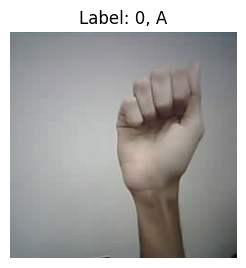

shape: (240, 240, 3)
tipo: float32
min: 7.0
max: 219.0
tipo: int8
min: -121
max: 91
Primeiros 100 valores da entrada realmente atribuída:
[ 77. 111. 112.  77. 111. 112.  77. 111. 112.  77. 111. 112.  77. 111.
 112.  77. 111. 112.  77. 111. 112.  77. 111. 112.  80. 114. 115.  80.
 114. 115.  80. 114. 115.  81. 115. 116.  81. 115. 116.  81. 115. 116.
  82. 116. 117.  84. 115. 117.  83. 111. 114.  85. 110. 114.  85. 110.
 114.  85. 110. 114.  85. 110. 114.  85. 110. 114.  85. 110. 114.  85.
 110. 114.  90. 115. 119.  90. 115. 119.  90. 115. 119.  90. 115. 119.
  91. 116. 120.  91. 116. 120.  92. 117. 121.  92. 117. 121.  96. 117.
 122.  96.]
Primeiros 100 valores da entrada realmente atribuída:
[-51 -17 -16 -51 -17 -16 -51 -17 -16 -51 -17 -16 -51 -17 -16 -51 -17 -16
 -51 -17 -16 -51 -17 -16 -48 -14 -13 -48 -14 -13 -48 -14 -13 -47 -13 -12
 -47 -13 -12 -47 -13 -12 -46 -12 -11 -44 -13 -11 -45 -17 -14 -43 -18 -14
 -43 -18 -14 -43 -18 -14 -43 -18 -14 -43 -18 -14 -43 -18 -14 -43 -18 -14
 -38 -1

In [ ]:
interpreter1 = tf.lite.Interpreter(model_content=converted1)
interpreter1.allocate_tensors()
print(interpreter1.get_input_details());
print(interpreter1.get_output_details());

interpreter2 = tf.lite.Interpreter(model_content=converted2)
interpreter2.allocate_tensors()
print(interpreter2.get_input_details());
print(interpreter2.get_output_details());

input1 = interpreter1.get_input_details()[0]      # dicionário tem apenas 1 elemento
output1 = interpreter1.get_output_details()[0]    # dicionário tem apenas 1 elemento
input2 = interpreter2.get_input_details()[0]      # dicionário tem apenas 1 elemento
input_scale = input2['quantization_parameters']['scales'][0]
input_zero_point = input2['quantization_parameters']['zero_points'][0]
output2 = interpreter2.get_output_details()[0]    # dicionário tem apenas 1 elemento
output_scale = output2['quantization_parameters']['scales'][0]
output_zero_point = output2['quantization_parameters']['zero_points'][0]

number_im = 25
# Pegando uma imagem
#batch_imgs = list(test_ds.take(1))[-1]
batch_imgs = next(iter(test_ds))   # pega um batch completo
images, labels = batch_imgs
print(images.shape)
print(labels.shape)
image = images[number_im].numpy().astype(np.float32)
label = int(np.argmax(labels[number_im].numpy()))
plt.figure(figsize=(10, 10))
ax = plt.subplot(3, 3, 1)
plt.imshow(images[number_im].numpy().astype("uint8"))
plt.title(f"Label: {label}, {class_names[label]}")
plt.axis("off")
plt.show()

print(f'shape: {image.shape}')
print(f'tipo: {image.dtype}')
print(f'min: {image.min()}')
print(f'max: {image.max()}')
img = (image/ input_scale + input_zero_point).astype(np.int8)
print(f'tipo: {img.dtype}')
print(f'min: {img.min()}')
print(f'max: {img.max()}')

# Ajustando shape e tipo
input_data1 = np.expand_dims(image, axis=0)
input_data2 = np.expand_dims(img, axis=0)

interpreter1.set_tensor(input1['index'], input_data1)
interpreter2.set_tensor(input2['index'], input_data2)

input_verificada1 = interpreter1.get_tensor(input1['index'])
print("Primeiros 100 valores da entrada realmente atribuída:")
print(input_verificada1.flatten()[:100])
input_verificada2 = interpreter2.get_tensor(input2['index'])
print("Primeiros 100 valores da entrada realmente atribuída:")
print(input_verificada2.flatten()[:100])

interpreter1.invoke()
interpreter2.invoke()

output_data1 = interpreter1.get_tensor(output1['index'])
output_data2 = interpreter2.get_tensor(output2['index'])

output1_array = np.array(output_data1)
output2_array = np.array(output_data2)
output_float2 = (output_data2.astype(np.float32) - output_zero_point) * output_scale
label_inf_NQ = np.argmax(output1_array)
label_inf_Q = np.argmax(output_float2)
print(f'in_ZP: {input_zero_point}')
print(f'in_scale: {input_scale}')
print(f'out_ZP: {output_zero_point}')
print(f'out_scale: {output_scale}')
print(f'saida modelo convertido (original_NQ): {output1_array}')
print(f'saida modelo convertido (original_Q): {output2_array}')
print(f'saida modelo convertido (desquantizado): {output_float2}')
print(f'label inferido (NQ): {class_names[label_inf_NQ]}')
print(f'label inferido (Q): {class_names[label_inf_Q]}')

def save_data_as_c_array(data, var_name, filename="input_data.h"):
    flat_data = data.flatten()
    with open(filename, "w") as f:
        f.write(f"const unsigned char {var_name}[] = {{\n    ")
        for i, val in enumerate(flat_data):
            f.write(f"{val}")
            if i != len(flat_data) - 1:
                f.write(", ")
            if (i + 1) % 20 == 0:
                f.write("\n    ")
        f.write("};\n")
        f.write(f"const int {var_name}_len = {len(flat_data)};\n")

# Salva
save_data_as_c_array(input_data2, "input_data1O", "input_data1O.h")

In [ ]:
open("RISQModel.tflite", "wb").write(converted1)

basic_model_size = os.path.getsize("RISQModel.tflite")

!echo "extern const unsigned char modelSQ[];"     > /content/modelSQ.h
!echo "extern const unsigned int modelSQ_len;"    >> /content/modelSQ.h

!echo "#include \"modelSQ.h\""                    > /content/modelSQ.cc
!echo "const unsigned char modelSQ[] = {"         >> /content/modelSQ.cc
!cat RISQModel.tflite | xxd -i                    >> /content/modelSQ.cc
!echo "};"                                        >> /content/modelSQ.cc
!echo -n "const unsigned int modelSQ_len = "      >> /content/modelSQ.cc
!echo -n "$basic_model_size"                      >> /content/modelSQ.cc
!echo ";"                                         >> /content/modelSQ.cc

model_cc_size = os.path.getsize("/content/modelSQ.cc")
print(f"cc file, model.cc, is {model_cc_size:,} bytes.")
print(f"model size is {basic_model_size} bytes.")
print("\nOpen the side panel (refresh if needed). Double click model.h and model.cc to download the files.")


open("RIQModel.tflite", "wb").write(converted2)

basic_model_size = os.path.getsize("RIQModel.tflite")

!echo "extern const unsigned char modelQ[];"      > /content/modelQ.h
!echo "extern const unsigned int modelQ_len;"     >> /content/modelQ.h

!echo "#include \"modelQ.h\""                     > /content/modelQ.cc
!echo "const unsigned char modelQ[] = {"          >> /content/modelQ.cc
!cat RIQModel.tflite | xxd -i                     >> /content/modelQ.cc
!echo "};"                                        >> /content/modelQ.cc
!echo -n "const unsigned int modelQ_len = "       >> /content/modelQ.cc
!echo -n "$basic_model_size"                      >> /content/modelQ.cc
!echo ";"                                         >> /content/modelQ.cc

model_cc_size = os.path.getsize("/content/modelQ.cc")
print(f"cc file, model.cc, is {model_cc_size:,} bytes.")
print(f"model size is {basic_model_size} bytes.")
print("\nOpen the side panel (refresh if needed). Double click model.h and model.cc to download the files.")

cc file, model.cc, is 14,137,133 bytes.
model size is 2292492 bytes.

Open the side panel (refresh if needed). Double click model.h and model.cc to download the files.
cc file, model.cc, is 3,571,533 bytes.
model size is 579152 bytes.

Open the side panel (refresh if needed). Double click model.h and model.cc to download the files.


In [ ]:
interpreter = tf.lite.Interpreter(model_path="RIQModel.tflite")
interpreter.allocate_tensors()

details = interpreter.get_tensor_details()
for d in details:
    name = d['name']
    dtype = d['dtype']
    qp = d.get('quantization_parameters', {})
    scales = qp.get('scales')
    zp = qp.get('zero_points')
    q = d.get('quantization')  # campo resumido (scale,zp)
    print(f"Tensor idx {d['index']:3d} name: {name:40.40} dtype:{dtype} quant:{q}")
    if scales is not None and len(scales)>0:
        print(f"    quant_params scales[0]: {scales[0]} zero_points[0]: {zp[0]}")